In [6]:
from google.colab import drive
drive.mount("/content/drive")

import os
import zipfile
from pathlib import Path
from PIL import Image

DRIVE_DIR = "/content/drive/MyDrive/TruthLens"
DATASET_DIR = f"{DRIVE_DIR}/dataset"
ZIP_PATH = f"{DATASET_DIR}/archive.zip"
EXTRACT_DIR = "/content/cifake"

os.makedirs(DATASET_DIR, exist_ok=True)
os.makedirs(f"{DRIVE_DIR}/checkpoints", exist_ok=True)
os.makedirs(f"{DRIVE_DIR}/results", exist_ok=True)
os.makedirs(f"{DRIVE_DIR}/final_model", exist_ok=True)

# Download the dataset ZIP from your Google Drive link
FILE_ID = "1eOUmknz6zh4hQVjApQaGG3zFw7pBxhAL"

if not os.path.exists(ZIP_PATH):
    import gdown
    gdown.download(
        f"https://drive.google.com/uc?id={FILE_ID}",
        ZIP_PATH,
        quiet=False,
        fuzzy=True
    )
else:
    print("ZIP already exists in TruthLens/dataset; skipping download.")

if not os.path.isfile(ZIP_PATH) or os.path.getsize(ZIP_PATH) == 0:
    raise RuntimeError(
        "ZIP download failed. Check that the Google Drive file is accessible."
    )

print("\nGoogle Drive connected.")
print("Dataset ZIP path:", ZIP_PATH)
print("ZIP size (MB):", round(os.path.getsize(ZIP_PATH) / (1024 * 1024), 2))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Downloading...
From (original): https://drive.google.com/uc?id=1eOUmknz6zh4hQVjApQaGG3zFw7pBxhAL
From (redirected): https://drive.google.com/uc?id=1eOUmknz6zh4hQVjApQaGG3zFw7pBxhAL&confirm=t&uuid=def42a1e-58ad-472e-8b99-9e9da8eb7069
To: /content/drive/MyDrive/TruthLens/dataset/archive.zip
100%|██████████| 110M/110M [00:01<00:00, 70.9MB/s]


Google Drive connected.
Dataset ZIP path: /content/drive/MyDrive/TruthLens/dataset/archive.zip
ZIP size (MB): 104.55


In [7]:
import zipfile

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    bad_file = z.testzip()

if bad_file:
    raise ValueError(f"ZIP corrupted! First bad file: {bad_file}")

print("ZIP integrity check passed ")

ZIP integrity check passed ✅


In [8]:
from pathlib import Path
import zipfile

Path(EXTRACT_DIR).mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

print("Extraction complete ")
print("Extracted to:", EXTRACT_DIR)

Extraction complete ✅
Extracted to: /content/cifake


In [9]:
from pathlib import Path

for split in ["train", "test"]:
    for label in ["REAL", "FAKE"]:
        folder = Path(EXTRACT_DIR) / split / label

        if not folder.is_dir():
            raise FileNotFoundError(f"Missing dataset folder: {folder}")

        count = sum(1 for p in folder.iterdir() if p.is_file())
        print(f"{split}/{label}: {count:,} files")

train/REAL: 50,000 files
train/FAKE: 50,000 files
test/REAL: 10,000 files
test/FAKE: 10,000 files


In [10]:
from pathlib import Path
from PIL import Image

bad_images = []
checked = 0

for split in ["train", "test"]:
    for label in ["REAL", "FAKE"]:
        folder = Path(EXTRACT_DIR) / split / label

        for path in folder.iterdir():
            if not path.is_file():
                continue

            try:
                with Image.open(path) as img:
                    img.verify()
                checked += 1
            except Exception:
                bad_images.append(str(path))

print("Readable images:", checked)
print("Corrupt images:", len(bad_images))

if bad_images:
    print("First 10 corrupt images:")
    print(*bad_images[:10], sep="\n")
else:
    print("All images are readable ")

Readable images: 120000
Corrupt images: 0
All images are readable ✅


In [11]:
import os
import json
import time
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.datasets import ImageFolder
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights
from sklearn.metrics import accuracy_score

# Reuse paths from Step 1
TRAIN_DIR = Path(EXTRACT_DIR) / "train"
TEST_DIR = Path(EXTRACT_DIR) / "test"

CHECKPOINT_DIR = Path(DRIVE_DIR) / "checkpoints"
RESULTS_DIR = Path(DRIVE_DIR) / "results"
FINAL_MODEL_DIR = Path(DRIVE_DIR) / "final_model"

for folder in [CHECKPOINT_DIR, RESULTS_DIR, FINAL_MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
VAL_RATIO = 0.10
IMAGE_SIZE = 224
BATCH_SIZE = 64
EPOCHS = 5
LEARNING_RATE = 0.0001
NUM_WORKERS = 2

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Pretrained ImageNet model normalization
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_base = ImageFolder(str(TRAIN_DIR), transform=train_transform)
val_base = ImageFolder(str(TRAIN_DIR), transform=val_transform)
test_dataset = ImageFolder(str(TEST_DIR), transform=val_transform)

assert train_base.classes == ["FAKE", "REAL"], (
    f"Unexpected class folders: {train_base.classes}"
)
assert test_dataset.classes == train_base.classes, (
    "Train/test class mappings do not match."
)

# Deterministic 90% train / 10% validation split
generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(train_base), generator=generator).tolist()
val_size = int(len(indices) * VAL_RATIO)

val_indices = indices[:val_size]
train_indices = indices[val_size:]

train_dataset = Subset(train_base, train_indices)
val_dataset = Subset(val_base, val_indices)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

print("\nClasses:", train_base.class_to_idx)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images (reserved for evaluation):", len(test_dataset))
print("Data loaders ready ✅")

Device: cuda
GPU: Tesla T4

Classes: {'FAKE': 0, 'REAL': 1}
Training images: 90000
Validation images: 10000
Test images (reserved for evaluation): 20000
Data loaders ready ✅


In [12]:
weights = MobileNet_V3_Small_Weights.DEFAULT
model = mobilenet_v3_small(weights=weights)

# Replace the final classifier for REAL vs FAKE
in_features = model.classifier[3].in_features
model.classifier[3] = nn.Linear(in_features, 2)

model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.0001
)

print("MobileNetV3-Small ready ✅")
print("Output classes:", train_base.classes)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 70.2MB/s]


MobileNetV3-Small ready ✅
Output classes: ['FAKE', 'REAL']


In [13]:
LATEST_CHECKPOINT = CHECKPOINT_DIR / "latest_checkpoint.pth"
BEST_MODEL_PATH = FINAL_MODEL_DIR / "truthlens_mobilenetv3_best.pth"
HISTORY_PATH = RESULTS_DIR / "training_history.json"

start_epoch = 0
best_val_accuracy = 0.0
history = []

# Resume automatically if a checkpoint already exists
if LATEST_CHECKPOINT.exists():
    checkpoint = torch.load(
        LATEST_CHECKPOINT,
        map_location=DEVICE,
        weights_only=False
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    start_epoch = checkpoint["epoch"] + 1
    best_val_accuracy = checkpoint.get("best_val_accuracy", 0.0)
    history = checkpoint.get("history", [])
    print(f"Resuming from epoch {start_epoch + 1}")

use_amp = DEVICE.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

for epoch in range(start_epoch, EPOCHS):
    epoch_start = time.time()

    # ---- Training ----
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda", enabled=use_amp):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # ---- Validation ----
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.amp.autocast("cuda", enabled=use_amp):
                outputs = model(images)
                loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total

    record = {
        "epoch": epoch + 1,
        "train_loss": round(train_loss, 5),
        "train_accuracy": round(train_accuracy, 5),
        "val_loss": round(val_loss, 5),
        "val_accuracy": round(val_accuracy, 5)
    }
    history.append(record)

    # Save best model
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            BEST_MODEL_PATH
        )

    # Save latest checkpoint after every epoch
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_val_accuracy": best_val_accuracy,
        "history": history,
        "class_to_idx": train_base.class_to_idx,
        "image_size": IMAGE_SIZE
    }, LATEST_CHECKPOINT)

    with open(HISTORY_PATH, "w") as f:
        json.dump(history, f, indent=2)

    elapsed = (time.time() - epoch_start) / 60

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2%} | "
        f"Time: {elapsed:.1f} min"
    )

print("\nTraining finished ✅")
print(f"Best validation accuracy: {best_val_accuracy:.2%}")
print("Best model:", BEST_MODEL_PATH)
print("Latest checkpoint:", LATEST_CHECKPOINT)

Epoch 1/5 | Train Loss: 0.1317 | Train Acc: 94.86% | Val Loss: 0.0988 | Val Acc: 96.20% | Time: 3.4 min
Epoch 2/5 | Train Loss: 0.0682 | Train Acc: 97.40% | Val Loss: 0.0620 | Val Acc: 97.62% | Time: 3.3 min
Epoch 3/5 | Train Loss: 0.0493 | Train Acc: 98.16% | Val Loss: 0.0559 | Val Acc: 98.05% | Time: 3.2 min
Epoch 4/5 | Train Loss: 0.0369 | Train Acc: 98.61% | Val Loss: 0.0493 | Val Acc: 98.35% | Time: 3.3 min
Epoch 5/5 | Train Loss: 0.0267 | Train Acc: 99.02% | Val Loss: 0.0521 | Val Acc: 98.07% | Time: 3.2 min

Training finished ✅
Best validation accuracy: 98.35%
Best model: /content/drive/MyDrive/TruthLens/final_model/truthlens_mobilenetv3_best.pth
Latest checkpoint: /content/drive/MyDrive/TruthLens/checkpoints/latest_checkpoint.pth


In [14]:
import pandas as pd

history_df = pd.DataFrame(history)
display(history_df)

print("Best validation accuracy:",
      f"{history_df['val_accuracy'].max():.2%}")

print("History saved at:", HISTORY_PATH)

,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,0.13170,0.94861,0.09878,0.9620
1,2,0.06821,0.97403,0.06201,0.9762
2,3,0.04927,0.98157,0.05594,0.9805
3,4,0.03687,0.98612,0.04929,0.9835
4,5,0.02672,0.99022,0.05209,0.9807


Best validation accuracy: 98.35%
History saved at: /content/drive/MyDrive/TruthLens/results/training_history.json


In [15]:
assert BEST_MODEL_PATH.exists(), "Best model file not found!"

class_mapping_path = FINAL_MODEL_DIR / "class_mapping.json"

with open(class_mapping_path, "w") as f:
    json.dump(train_base.class_to_idx, f, indent=2)

print("Best model size (MB):",
      round(BEST_MODEL_PATH.stat().st_size / (1024 * 1024), 2))
print("Class mapping:", train_base.class_to_idx)
print("Model and class mapping saved successfully ✅")

Best model size (MB): 5.93
Class mapping: {'FAKE': 0, 'REAL': 1}
Model and class mapping saved successfully ✅


In [16]:
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision.transforms as transforms

from PIL import Image, ImageFilter
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from torchvision.models import mobilenet_v3_small
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from pathlib import Path

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TEST_DIR = Path(EXTRACT_DIR) / "test"
RESULTS_DIR = Path(DRIVE_DIR) / "results"
FINAL_MODEL_DIR = Path(DRIVE_DIR) / "final_model"

BEST_MODEL_PATH = FINAL_MODEL_DIR / "truthlens_mobilenetv3_best.pth"

assert BEST_MODEL_PATH.exists(), f"Model file not found: {BEST_MODEL_PATH}"

IMAGE_SIZE = 224
BATCH_SIZE = 64
CLASS_NAMES = ["FAKE", "REAL"]

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_dataset = ImageFolder(str(TEST_DIR), transform=eval_transform)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

model = mobilenet_v3_small(weights=None)
model.classifier[3] = nn.Linear(model.classifier[3].in_features, 2)

state_dict = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=True
)
model.load_state_dict(state_dict)
model = model.to(DEVICE)
model.eval()

print("Evaluation model loaded ✅")
print("Device:", DEVICE)
print("Test images:", len(test_dataset))
print("Class mapping:", test_dataset.class_to_idx)

Evaluation model loaded ✅
Device: cuda
Test images: 20000
Class mapping: {'FAKE': 0, 'REAL': 1}


In [17]:
all_labels = []
all_predictions = []
all_probabilities = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)

        logits = model(images)
        probabilities = torch.softmax(logits, dim=1)
        predictions = logits.argmax(dim=1)

        all_labels.extend(labels.numpy().tolist())
        all_predictions.extend(predictions.cpu().numpy().tolist())
        all_probabilities.extend(probabilities.cpu().numpy().tolist())

accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(
    all_labels, all_predictions, pos_label=1, zero_division=0
)
recall = recall_score(
    all_labels, all_predictions, pos_label=1, zero_division=0
)
f1 = f1_score(
    all_labels, all_predictions, pos_label=1, zero_division=0
)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nClassification report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=[0, 1],
    target_names=CLASS_NAMES,
    zero_division=0
))

cm = confusion_matrix(all_labels, all_predictions, labels=[0, 1])
print("Confusion matrix (rows=true, columns=predicted):")
print(pd.DataFrame(
    cm,
    index=["True FAKE", "True REAL"],
    columns=["Predicted FAKE", "Predicted REAL"]
))

metrics = {
    "accuracy": float(accuracy),
    "precision_real": float(precision),
    "recall_real": float(recall),
    "f1_real": float(f1),
    "class_names": CLASS_NAMES,
    "confusion_matrix": cm.tolist(),
    "test_images": len(test_dataset)
}

with open(RESULTS_DIR / "test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("\nMetrics saved to Google Drive ✅")

Accuracy:  0.9828
Precision: 0.9855
Recall:    0.9799
F1-score:  0.9827

Classification report:
              precision    recall  f1-score   support

        FAKE       0.98      0.99      0.98     10000
        REAL       0.99      0.98      0.98     10000

    accuracy                           0.98     20000
   macro avg       0.98      0.98      0.98     20000
weighted avg       0.98      0.98      0.98     20000

Confusion matrix (rows=true, columns=predicted):
           Predicted FAKE  Predicted REAL
True FAKE            9856             144
True REAL             201            9799

Metrics saved to Google Drive ✅


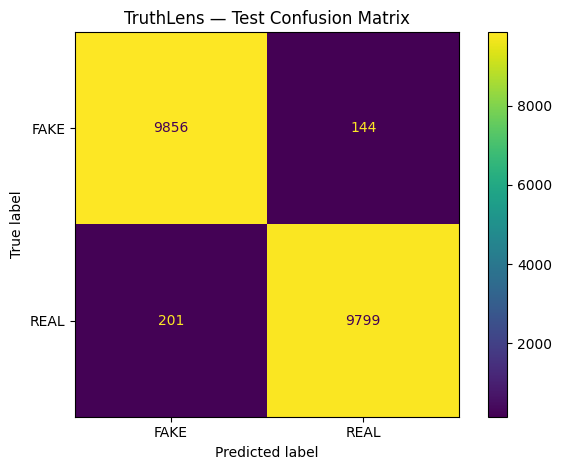

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)
display.plot(values_format="d")
plt.title("TruthLens — Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "confusion_matrix.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

In [19]:
import io
from torch.utils.data import Dataset, DataLoader

class RobustnessDataset(Dataset):
    def __init__(self, base_dataset, mode):
        self.base_dataset = base_dataset
        self.mode = mode

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        path, label = self.base_dataset.samples[idx]

        with Image.open(path) as img:
            image = img.convert("RGB")

        if self.mode == "jpeg":
            buffer = io.BytesIO()
            image.save(buffer, format="JPEG", quality=40)
            buffer.seek(0)
            image = Image.open(buffer).convert("RGB")

        elif self.mode == "blur":
            image = image.filter(ImageFilter.GaussianBlur(radius=1.5))

        elif self.mode == "resize":
            image = image.resize((112, 112)).resize((224, 224))

        tensor = eval_transform(image)
        return tensor, label

def predict_loader(loader):
    predictions = []
    labels = []

    model.eval()
    with torch.no_grad():
        for images, targets in loader:
            images = images.to(DEVICE)
            logits = model(images)
            predictions.extend(logits.argmax(1).cpu().numpy().tolist())
            labels.extend(targets.numpy().tolist())

    return np.array(labels), np.array(predictions)

# Compare with predictions from the unmodified test images
original_labels = np.array(all_labels)
original_predictions = np.array(all_predictions)

robustness_results = []

for mode in ["jpeg", "blur", "resize"]:
    dataset = RobustnessDataset(test_dataset, mode)
    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=(DEVICE.type == "cuda")
    )

    labels, predictions = predict_loader(loader)

    result = {
        "transformation": mode,
        "accuracy": float(accuracy_score(labels, predictions)),
        "f1": float(f1_score(labels, predictions, zero_division=0)),
        "prediction_consistency": float(
            np.mean(predictions == original_predictions)
        )
    }
    robustness_results.append(result)

    print(
        f"{mode.upper():>6} | "
        f"Accuracy: {result['accuracy']:.4f} | "
        f"F1: {result['f1']:.4f} | "
        f"Consistency: {result['prediction_consistency']:.2%}"
    )

with open(RESULTS_DIR / "robustness_results.json", "w") as f:
    json.dump(robustness_results, f, indent=2)

print("\nRobustness results saved ✅")

  JPEG | Accuracy: 0.9266 | F1: 0.9305 | Consistency: 93.11%
  BLUR | Accuracy: 0.6059 | F1: 0.6103 | Consistency: 60.89%
RESIZE | Accuracy: 0.9748 | F1: 0.9747 | Consistency: 98.14%

Robustness results saved ✅


In [20]:
import os
import zipfile
from google.colab import files

DRIVE_DIR = "/content/drive/MyDrive/TruthLens"
PACKAGE_PATH = "/content/truthlens_model_bundle.zip"

required_files = [
    "final_model/truthlens_mobilenetv3_best.pth",
    "final_model/class_mapping.json",
    "results/test_metrics.json",
    "results/confusion_matrix.png",
    "results/robustness_results.json",
    "results/training_history.json",
]

with zipfile.ZipFile(PACKAGE_PATH, "w", zipfile.ZIP_DEFLATED) as z:
    for relative_path in required_files:
        full_path = os.path.join(DRIVE_DIR, relative_path)

        if os.path.isfile(full_path):
            z.write(full_path, arcname=relative_path)
            print("Added:", relative_path)
        else:
            print("Skipped (not found):", relative_path)

files.download(PACKAGE_PATH)

Added: final_model/truthlens_mobilenetv3_best.pth
Added: final_model/class_mapping.json
Added: results/test_metrics.json
Added: results/confusion_matrix.png
Added: results/robustness_results.json
Added: results/training_history.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
import random

for _ in range(10):
    idx = random.randrange(len(test_dataset))
    image, actual_label = test_dataset[idx]

    with torch.no_grad():
        logits = model(image.unsqueeze(0).to(DEVICE))
        predicted_label = logits.argmax(dim=1).item()

    print(
        f"Actual: {test_dataset.classes[actual_label]:<5} | "
        f"Predicted: {test_dataset.classes[predicted_label]}"
    )

Actual: FAKE  | Predicted: FAKE
Actual: FAKE  | Predicted: FAKE
Actual: FAKE  | Predicted: FAKE
Actual: FAKE  | Predicted: REAL
Actual: FAKE  | Predicted: FAKE
Actual: FAKE  | Predicted: FAKE
Actual: FAKE  | Predicted: FAKE
Actual: REAL  | Predicted: REAL
Actual: FAKE  | Predicted: FAKE
Actual: REAL  | Predicted: REAL


In [22]:
from collections import Counter

model.eval()
actual_real_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        predictions = model(images).argmax(dim=1)

        real_mask = labels == test_dataset.class_to_idx["REAL"]
        actual_real_predictions.extend(
            predictions[real_mask].cpu().tolist()
        )

print("REAL images tested:", len(actual_real_predictions))
print("Predictions:", Counter(actual_real_predictions))
print("Class mapping:", test_dataset.class_to_idx)

REAL images tested: 10000
Predictions: Counter({1: 9799, 0: 201})
Class mapping: {'FAKE': 0, 'REAL': 1}
